<a href="https://colab.research.google.com/github/Adnan1507/research-experiment/blob/experiment/experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Data loading and EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = 'https://raw.githubusercontent.com/Adnan1507/research-experiment/main/diabetes.csv'
df = pd.read_csv(url)
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
print(df.dtypes)
print(df.describe().T)
print(df['Outcome'].value_counts())

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object
                          count        mean         std     min       25%  \
Pregnancies               768.0    3.845052    3.369578   0.000   1.00000   
Glucose                   768.0  120.894531   31.972618   0.000  99.00000   
BloodPressure             768.0   69.105469   19.355807   0.000  62.00000   
SkinThickness             768.0   20.536458   15.952218   0.000   0.00000   
Insulin                   768.0   79.799479  115.244002   0.000   0.00000   
BMI                       768.0   31.992578    7.884160   0.000  27.30000   
DiabetesPedigreeFunction  768.0    0.471876    0.331329   0.078   0.24375   
Age                       768.0   33.240885   

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


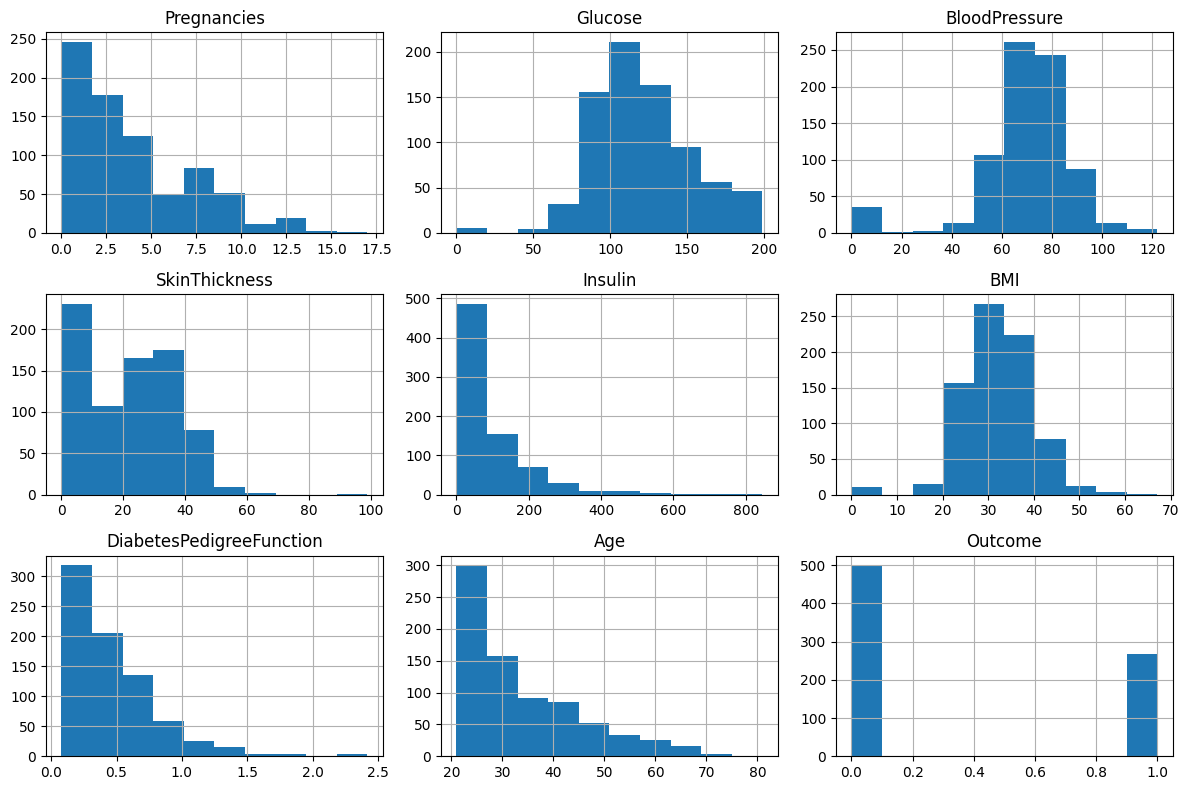

In [3]:
cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print((df[cols] == 0).sum())
df.hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

#Clean the data and split it

In [4]:
print('Duplicate rows:', df.duplicated().sum())
print('Real NaN values:', df.isna().sum().sum())

df_clean = df.copy()
df_clean[cols] = df_clean[cols].replace(0, np.nan)
print(df_clean.isna().sum())

Duplicate rows: 0
Real NaN values: 0
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [5]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns='Outcome')
y = df_clean['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(614, 8) (154, 8)
0.3485342019543974 0.35064935064935066


#Feature engineering

In [6]:
from sklearn.impute import SimpleImputer

X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

# Flag rows where Insulin / SkinThickness were missing (before filling them)
for c in ['Insulin', 'SkinThickness']:
    X_train_fe[c + '_missing'] = X_train[c].isna().astype(int)
    X_test_fe[c + '_missing'] = X_test[c].isna().astype(int)

# Fill gaps with the median, learned from the training set only
orig_cols = list(X_train.columns)
imputer = SimpleImputer(strategy='median')
X_train_fe[orig_cols] = imputer.fit_transform(X_train[orig_cols])
X_test_fe[orig_cols] = imputer.transform(X_test[orig_cols])

print(X_train_fe.isna().sum().sum(), X_test_fe.isna().sum().sum())

0 0


In [7]:
for d in (X_train_fe, X_test_fe):
    d['Glucose_BMI'] = d['Glucose'] * d['BMI']
    d['Age_group'] = pd.cut(d['Age'], bins=[20, 30, 40, 50, 120],
                            labels=[0, 1, 2, 3]).astype(int)

print(X_train_fe.shape, X_test_fe.shape)
X_train_fe.head()

(614, 12) (154, 12)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Insulin_missing,SkinThickness_missing,Glucose_BMI,Age_group
353,1.0,90.0,62.0,12.0,43.0,27.2,0.580,24.0,0,0,2448.0,0
711,5.0,126.0,78.0,27.0,22.0,29.6,0.439,40.0,0,0,3729.6,1
373,2.0,105.0,58.0,40.0,94.0,34.9,0.225,25.0,0,0,3664.5,0
46,1.0,146.0,56.0,29.0,125.0,29.7,0.564,29.0,1,1,4336.2,0
682,0.0,95.0,64.0,39.0,105.0,44.6,0.366,22.0,0,0,4237.0,0


In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_fe)
X_test_scaled = scaler.transform(X_test_fe)

print(X_train_scaled.shape, X_test_scaled.shape)

(614, 12) (154, 12)


#Train the baseline model

In [9]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)
print('Logistic regression trained')

Logistic regression trained


#Train the second model

In [10]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, random_state=42)
rf.fit(X_train_fe, y_train)
print('Random forest trained')

Random forest trained


#Evaluation

In [11]:
from sklearn.metrics import (roc_auc_score, recall_score, f1_score,
                             accuracy_score, precision_score)

# Predictions
lr_pred = log_reg.predict(X_test_scaled)
lr_prob = log_reg.predict_proba(X_test_scaled)[:, 1]
rf_pred = rf.predict(X_test_fe)
rf_prob = rf.predict_proba(X_test_fe)[:, 1]

results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'ROC-AUC': [roc_auc_score(y_test, lr_prob), roc_auc_score(y_test, rf_prob)],
    'Recall': [recall_score(y_test, lr_pred), recall_score(y_test, rf_pred)],
    'Precision': [precision_score(y_test, lr_pred), precision_score(y_test, rf_pred)],
    'F1': [f1_score(y_test, lr_pred), f1_score(y_test, rf_pred)],
    'Accuracy': [accuracy_score(y_test, lr_pred), accuracy_score(y_test, rf_pred)],
}).round(3)
results

,Model,ROC-AUC,Recall,Precision,F1,Accuracy
0,Logistic Regression,0.819,0.519,0.596,0.554,0.708
1,Random Forest,0.820,0.593,0.653,0.621,0.747


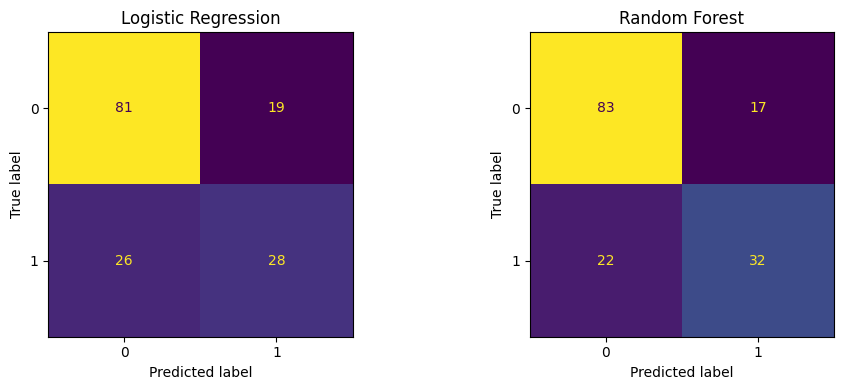

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, lr_pred, ax=axes[0], colorbar=False)
axes[0].set_title('Logistic Regression')
ConfusionMatrixDisplay.from_predictions(y_test, rf_pred, ax=axes[1], colorbar=False)
axes[1].set_title('Random Forest')
plt.tight_layout()
plt.show()

In [13]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr_cv = cross_val_score(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    X_train_fe, y_train, cv=cv, scoring='roc_auc')
rf_cv = cross_val_score(
    RandomForestClassifier(n_estimators=300, random_state=42),
    X_train_fe, y_train, cv=cv, scoring='roc_auc')

print(f'Logistic Regression CV ROC-AUC: {lr_cv.mean():.3f} (+/- {lr_cv.std():.3f})')
print(f'Random Forest CV ROC-AUC:       {rf_cv.mean():.3f} (+/- {rf_cv.std():.3f})')

Logistic Regression CV ROC-AUC: 0.847 (+/- 0.019)
Random Forest CV ROC-AUC:       0.824 (+/- 0.026)


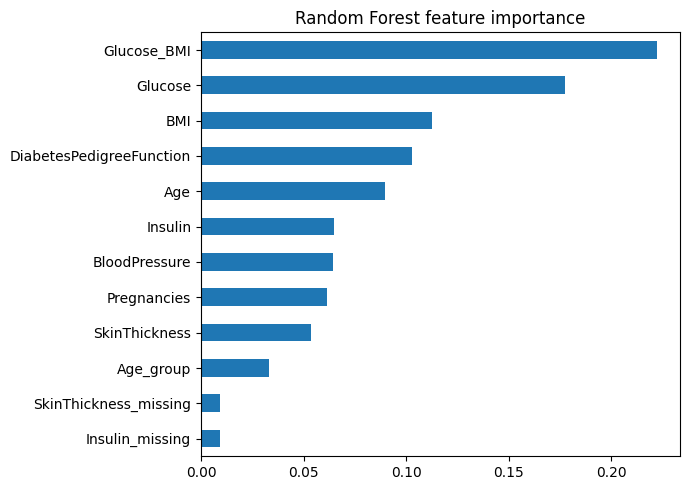

In [14]:
importances = pd.Series(rf.feature_importances_, index=X_train_fe.columns).sort_values()
importances.plot(kind='barh', figsize=(7, 5), title='Random Forest feature importance')
plt.tight_layout()
plt.show()

## Conclusion

On the held-out test set, random forest and logistic regression had almost identical ROC-AUC (0.820 vs 0.819), but random forest did better on recall (0.593 vs 0.519), F1 (0.621 vs 0.554) and accuracy (0.747 vs 0.708). In 5-fold cross-validation, however, logistic regression scored higher (0.847 vs 0.824), so the more complex model did not clearly win, which agrees with earlier studies that found simple models competitive on this dataset. Both models caught only about half to 60% of the diabetic cases, which is a real weakness because missing a patient is the costlier mistake. My accuracy of 71-75% is in line with most published results and well below the 88% one paper claimed, which supports my caution about that figure. With only 154 test rows, a few points of difference could easily come from the random split rather than from the models themselves. With more time I would tune the hyperparameters, lower the decision threshold to raise recall, try gradient boosting and SVM, use repeated cross-validation, and test a better imputation method such as KNN imputation.